## Exploración de datos
### Tabla de pedidos

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

orders = pd.read_csv("archive/olist_orders_dataset.csv")
print(orders.shape)
print(orders.head())
orders.info()

(99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00       

La tabla de pedidos tiene 99.441 filas y 8 columnas. Las columnas de fechas están guardadas como texto, así que habrá que convertirlas antes de poder restarlas. Además, faltan valores en tres de ellas: 160 en `order_approved_at`, 1.783 en `order_delivered_carrier_date` y 2.965 en `order_delivered_customer_date`.

In [3]:
print(orders["order_status"].value_counts())
print(orders.isna().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


El estado más común es `delivered` (96.478 pedidos); el resto se reparte entre `shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created` y `approved`.

In [4]:
sin_fecha = orders[orders["order_delivered_customer_date"].isna()]
print(sin_fecha["order_status"].value_counts())

entregados_sin_fecha = orders[(orders["order_status"] == "delivered") & (orders["order_delivered_customer_date"].isna())]
print(entregados_sin_fecha.shape)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64
(8, 8)


De los 2.965 pedidos sin fecha de entrega, la mayoría no figura como entregada (`shipped`: 1.107, `canceled`: 619, `unavailable`: 609, entre otros). Sin embargo, 8 pedidos figuran como `delivered` y no tienen fecha de entrega. No se puede saber la causa con estos datos; podría ser un error de carga o un cambio de estado posterior.

In [5]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])

orders["dias_entrega"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
print(orders["dias_entrega"].describe())

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: dias_entrega, dtype: float64


Se calculó el tiempo de entrega como los días entre la fecha de compra y la fecha de entrega al cliente, para los 96.476 pedidos que tienen ambos datos. En promedio una entrega tarda 12,1 días y la mitad tarda 10 días o menos; el 75% llega en 15 días o menos. El mínimo es 0 días (menos de 24 horas) y el máximo es 209, muy lejos del resto de los valores.

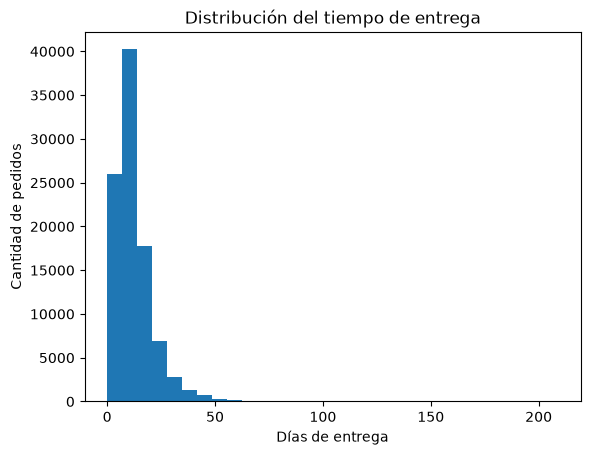

In [6]:
plt.hist(orders["dias_entrega"].dropna(), bins=30)
plt.xlabel("Días de entrega")
plt.ylabel("Cantidad de pedidos")
plt.title("Distribución del tiempo de entrega")
plt.show()

In [7]:
print((orders["dias_entrega"] > 60).sum())
print((orders["dias_entrega"] > 100).sum())
print((orders["dias_entrega"] > 150).sum())

288
63
24


In [8]:
print((orders["dias_entrega"] > 60).sum() / orders["dias_entrega"].notna().sum())

0.002985198391309756


En los datos y en el gráfico se puede apreciar que la mitad de los pedidos tarda 10 días o menos y el 75% llega para los 15 días, los demás llegan a los 60 días o menos. Sin embargo, hay una minoría, 0,3%, que llega luego de los 60 días, son un total de 288 de los 96.476 pedidos con fecha de entrega. De estos 288, 63 superaron los 100 días y 24 los 150. Los datos no revelan por qué estos pedidos llegan tan tarde, una hipótesis es que se trata de pedidos en zonas lejanas del país o pedidos que se extravían y se vuelven a recuperar.

### Tabla de clientes

In [9]:
customers = pd.read_csv("archive/olist_customers_dataset.csv")
print(customers.shape)
print(customers.head())
customers.info()

(99441, 5)
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count

In [10]:
print(customers["customer_id"].nunique())
print(customers["customer_unique_id"].nunique())

99441
96096


La tabla de clientes tiene 99.441 filas y 5 columnas, sin valores nulos. Tiene dos identificadores: `customer_id`, con 99.441 valores distintos (uno por fila), y `customer_unique_id`, con 96.096. Esa diferencia indica que algunos clientes aparecen en más de una fila.

In [11]:
filas_por_persona = customers["customer_unique_id"].value_counts()
print(filas_por_persona.value_counts())

count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
17        1
9         1
Name: count, dtype: int64


De esos 96.096 clientes, 93.099 aparecen en una sola fila y el resto en 2 o más, hasta un máximo de 17.

### Unión de pedidos y clientes

In [12]:
pedidos_clientes = pd.merge(orders, customers, on="customer_id", how="left")
print(pedidos_clientes.shape)
print(pedidos_clientes["customer_unique_id"].isna().sum())
print(pedidos_clientes["customer_unique_id"].value_counts().value_counts())

(99441, 13)
0
count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
17        1
9         1
Name: count, dtype: int64


Al unir la tabla de pedidos con la de clientes por `customer_id`, el resultado mantiene las 99.441 filas y no hay ningún nulo en `customer_unique_id`, es decir, todos los pedidos encontraron a su cliente. La distribución de pedidos por persona es la misma que la de filas por persona, en la tabla de clientes 93.099 personas tienen un solo pedido y el máximo es 17.

In [13]:
entregados = pedidos_clientes[pedidos_clientes["order_status"] == "delivered"]
print(entregados["customer_unique_id"].nunique())
print(entregados["customer_unique_id"].value_counts().value_counts())

93358
count
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
15        1
9         1
Name: count, dtype: int64


In [14]:
total = entregados["customer_unique_id"].nunique()
una_compra = (entregados["customer_unique_id"].value_counts() == 1).sum()
print(una_compra / total)
print(1 - una_compra / total)

0.9699972150217443
0.030002784978255703


### Definición de la variable a predecir

Se define que un cliente "volvió" si realizó más de una compra entregada, sin importar cuánto tiempo pasó entre ellas. Se eligió esta definición, en lugar de la de 30 días del enunciado, porque un cliente puede volver a comprar a los dos o tres meses y no por eso se fue. Entre las personas con pedidos entregados, el 97% compró una sola vez y el 3% más de una.

In [15]:
compras_por_persona = entregados["customer_unique_id"].value_counts()
volvio = compras_por_persona > 1
print(volvio.value_counts())

count
False    90557
True      2801
Name: count, dtype: int64


De las 93.358 personas con pedidos entregados, 2.801 volvieron a comprar y 90.557 compraron no volvieron a comprar.

### Tabla de reseñas

In [16]:
reviews = pd.read_csv("archive/olist_order_reviews_dataset.csv")
print(reviews.shape)
reviews.info()

(99224, 7)
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [17]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [18]:
print(reviews["order_id"].nunique())
print(reviews["review_score"].value_counts())

98673
review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64


La tabla de reseñas tiene 99.224 filas y 7 columnas. Solo faltan valores en el título y el mensaje del comentario, el `review_score` está completo. Las puntuaciones van de 1 a 5 y la más frecuente es 5, con 57.328 reseñas. Hay 98.673 pedidos distintos, menos que las filas, lo que indica que algunos pedidos tienen más de una reseña.

In [19]:
reseñas_por_pedido = reviews["order_id"].value_counts()
reseñas_por_pedido.value_counts()

count
1    98126
2      543
3        4
Name: count, dtype: int64

Se comprobó cuántas reseñas tiene cada pedido: 98.126 pedidos tienen una, 543 tienen dos y 4 tienen tres. Como el modelo necesita un único puntaje por pedido, habrá que quedarse con una sola reseña en los pedidos que tienen más de una.

In [20]:
reviews_unicas = reviews.sort_values("review_answer_timestamp").drop_duplicates(subset="order_id", keep="last")
reviews_unicas.shape

(98673, 7)

En los pedidos con más de una reseña se conservó la más reciente, según `review_answer_timestamp`, ya que refleja la opinión final del cliente.

In [21]:
entregados_resenas = pd.merge(entregados, reviews_unicas[["order_id", "review_score"]], on="order_id", how="left")
print(entregados_resenas.shape)
print(entregados_resenas["review_score"].isna().sum())

(96478, 14)
646


Al agregar las reseñas a los pedidos entregados, la tabla mantiene las 96.478 filas. De ellas, 646 pedidos no tienen reseña.

### Tabla por cliente (primer pedido)

In [22]:
primeros = entregados_resenas.sort_values("order_purchase_timestamp").drop_duplicates(subset="customer_unique_id")
primeros.shape

(93358, 14)

Se armó una tabla con una fila por persona, tomando solo los datos de su primer pedido entregado, en total tiene 93.358 filas, una por cada persona con al menos un pedido entregado. Así las características, como el tiempo de entrega o la reseña, corresponden a esa primera compra y no a compras posteriores, que solo existen si la persona volvió.

In [23]:
primeros["volvio"] = primeros["customer_unique_id"].map(volvio)
primeros["volvio"].value_counts()

volvio
False    90557
True      2801
Name: count, dtype: int64

Se agregó a la tabla la columna `volvio`, que vale `True` si la persona compró más de una vez. 2.801 personas volvieron a comprar y 90.557 compraron una sola vez.

In [24]:
primeros[["dias_entrega", "customer_state", "review_score"]].isna().sum()

dias_entrega        8
customer_state      0
review_score      616
dtype: int64

En la tabla por persona hay 8 valores nulos en `dias_entrega`, los pedidos entregados sin fecha de entrega, y 616 en `review_score`, las personas cuyo primer pedido no tiene reseña. `customer_state` no tiene nulos.

Los valores vacíos de `dias_entrega` y de `review_score` no se borran, se rellenarán con la mediana, calculada solo con los datos de entrenamiento y dentro del pipeline para evitar fuga de datos. Se eligió la mediana porque siempre da un valor real de la escala de estrellas y porque el tiempo de entrega tiene una cola larga que estira el promedio.

### Separación en entrenamiento y prueba

In [25]:
X = primeros[["dias_entrega", "customer_state", "review_score"]]
y = primeros["volvio"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=36, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(74686, 3) (18672, 3)
volvio
False    0.969994
True     0.030006
Name: proportion, dtype: float64
volvio
False    0.970009
True     0.029991
Name: proportion, dtype: float64


Los datos se separaron en 80% para entrenamiento, 74.686 personas, y 20% para prueba, son 18.672. Como solo el 3% de las personas volvió a comprar, se usó `stratify` para que ambos grupos conserven esa proporción, en los dos, cerca del 97% no volvió y cerca del 3% sí.

In [26]:
primeros["customer_state"].nunique()

27

La columna `customer_state` tiene 27 valores distintos, se convierte con One-Hot Encoding, sin eliminar ninguna categoría, porque los modelos de esta comparación no tienen la redundancia que sí afecta a la regresión lineal.

### Preprocesamiento

In [27]:
numericas = ["dias_entrega", "review_score"]
categoricas = ["customer_state"]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
preprocesador = ColumnTransformer([("num", num_pipe, numericas), ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])

X_train_prep = preprocesador.fit_transform(X_train)
print(X_train_prep.shape)

(74686, 29)


El preprocesamiento se arma con un `ColumnTransformer`, las columnas numéricas, que son `dias_entrega` y `review_score`, se rellenan con la mediana y se escalan, y `customer_state` se convierte con One-Hot. Aplicado al conjunto de entrenamiento, el resultado tiene 74.686 filas y 29 columnas, 2 numéricas y 27 estados.

In [28]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_prep, y_train)
pred = dummy.predict(preprocesador.transform(X_test))
print(accuracy_score(y_test, pred))
print(recall_score(y_test, pred))

0.9700085689802913
0.0


Como modelo de base se usó un clasificador que responde siempre la clase más frecuente, "no volvió". Sobre el conjunto de prueba obtiene una accuracy de 0,970 y un recall de 0,0 para los clientes que sí vuelven. Esto muestra que, con clases tan desbalanceadas, la accuracy por sí sola no sirve para comparar modelos, un modelo que no detecta a nadie ya alcanza el 97%.

Para comparar los modelos se usara el F1 de la clase "volvió", porque combina Precision y Recall y no se infla con la clase mayoritaria, el modelo de base alcanzó 97% de accuracy con un recall de 0,0.

## Misión 1

### Comparación de modelos
#### Decision Tree

In [29]:
pipe_arbol = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(random_state=42))])
res = cross_validate(pipe_arbol, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
print(res["train_score"])
print(res["test_score"])

[0.0436443  0.03936577 0.03399123 0.03721949 0.04257642]
[0. 0. 0. 0. 0.]


In [30]:
print(X_train.drop_duplicates().shape)

(4251, 3)


El Decision Tree sin límite de profundidad obtuvo en la cross-validation un F1 de entre 0,034 y 0,044 en train y de 0 en test en las 5 vueltas, igual que el modelo de base. En el conjunto de entrenamiento hay 4.251 combinaciones distintas de valores entre 74.686 filas, es decir, muchas personas comparten exactamente las mismas características.

In [31]:
arbol_a = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(max_depth=5, random_state=42))])
arbol_b = Pipeline([("prep", preprocesador), ("modelo", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))])

for nombre, pipe in [("A: max_depth=5", arbol_a), ("B: max_depth=5 + balanced", arbol_b)]:
    res = cross_validate(pipe, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
    print(nombre)
    print(res["train_score"])
    print(res["test_score"])

A: max_depth=5
[0.00222965 0.00334076 0.00111483 0.00334076 0.00334076]
[0. 0. 0. 0. 0.]
B: max_depth=5 + balanced
[0.06197783 0.06939959 0.06175963 0.06368551 0.06222026]
[0.05915661 0.06180631 0.05741077 0.05969022 0.06178862]


Se probó el Decision Tree con profundidad máxima 5, sin y con `class_weight="balanced"`. Sin balanceo el F1 en test fue 0 en las 5 vueltas, igual que el modelo de base. Con balanceo, el F1 en test fue de entre 0,057 y 0,062 y el de train de entre 0,062 y 0,069, no hay brecha entre los dos, pero ambos son bajos.

In [32]:
dummy_todos = DummyClassifier(strategy="constant", constant=True)
res = cross_validate(dummy_todos, X_train, y_train, cv=5, scoring="f1")
res["test_score"]

array([0.05836095, 0.05823854, 0.05823854, 0.05823854, 0.05823854])

Como segundo punto de comparación se usó un clasificador que responde siempre "volvió". Su F1 en test es de 0,058 en las 5 vueltas, prácticamente igual al del Decision Tree balanceado (entre 0,057 y 0,062). Es decir, ese árbol no logra superar claramente a un modelo que no mira ninguna característica del cliente.

In [33]:
pred_b = cross_val_predict(arbol_b, X_train, y_train, cv=5)
confusion_matrix(y_train, pred_b)

array([[31605, 40840],
       [  918,  1323]])

La matriz de confusión del Decision Tree balanceado, obtenida con cross-validation sobre el entrenamiento, muestra 31.605 verdaderos negativos, 40.840 falsos positivos, 918 falsos negativos y 1.323 verdaderos positivos. El modelo detecta a buena parte de los clientes que vuelven, pero a costa de marcar como "volvió" a muchísimos que no volvieron.

In [34]:
print(precision_score(y_train, pred_b))
print(recall_score(y_train, pred_b))

0.03137822261224296
0.5903614457831325


El Decision Tree balanceado obtiene una Precision de 0,031 y un Recall de 0,590 en la cross-validation sobre el entrenamiento. La Precision es prácticamente igual a la proporción de clientes que vuelven en los datos (3%), por lo que marcar a un cliente como "volvió" no aporta información sobre si realmente volverá. El modelo detecta a casi 6 de cada 10 clientes que vuelven, pero a costa de marcar como "volvió" a más de la mitad de todos los clientes.

In [35]:
resultados = {}

def evaluar(nombre, modelo):
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
    resultados[nombre] = {"F1 train": res["train_score"].mean(), "F1 test": res["test_score"].mean()}
    print(nombre)
    print(res["train_score"].round(3))
    print(res["test_score"].round(3))

evaluar("Decision Tree", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))

Decision Tree
[0.062 0.069 0.062 0.064 0.062]
[0.059 0.062 0.057 0.06  0.062]


#### Random Forest

In [37]:
evaluar("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42))

Random Forest
[0.071 0.07  0.071 0.071 0.071]
[0.06  0.057 0.06  0.06  0.062]


El Random Forest de 100 árboles, profundidad máxima 5, con `class_weight="balanced"`, obtuvo en la cross-validation un F1 de entre 0,070 y 0,071 en train y de entre 0,057 y 0,062 en test. Hay una brecha pequeña, pero ambos valores son muy bajos y el resultado en test es prácticamente igual al del Decision Tree y al de un modelo que responde siempre "volvió".

#### Gradient Boosting

In [39]:
evaluar("Gradient Boosting", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))

Gradient Boosting
[0.004 0.002 0.003 0.006 0.004]
[0. 0. 0. 0. 0.]


El Gradient Boosting con 100 árboles, `learning_rate` 0,1 y profundidad 3, el modelo no admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,002 y 0,006 en train y de 0 en test en las 5 vueltas, casi nunca predice que el cliente vuelve, igual que el Decision Tree sin balancear y que el modelo de base.

#### kNN

In [41]:
evaluar("kNN", KNeighborsClassifier(n_neighbors=5))

kNN
[0.011 0.007 0.003 0.006 0.011]
[0.004 0.    0.    0.    0.   ]


El kNN, con k = 5, tampoco admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,003 y 0,011 en train y de 0 en casi todas las vueltas en test, 0,004 en la primera. Casi nunca predice que el cliente vuelve, ya que para eso la mayoría de sus 5 vecinos tendría que haber vuelto y solo el 3% lo hizo.

#### Naive Bayes

In [43]:
# 1) Preprocesador igual al de los otros modelos, pero que devuelve una tabla común
#    (sparse_threshold=0) y no una matriz dispersa, porque GaussianNB no acepta esa
prep_denso = ColumnTransformer(
    [("num", num_pipe, numericas),                                    # números: mediana + escalado
     ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)],   # estado: One-Hot
    sparse_threshold=0
)

# 2) Pipeline: primero el preprocesador, después el modelo
pipe_nb = Pipeline([("prep", prep_denso), ("modelo", GaussianNB())])

# 3) Cross-validation con 5 vueltas y F1, guardando también el resultado en train
res = cross_validate(pipe_nb, X_train, y_train, cv=5, scoring="f1", return_train_score=True)

# 4) Guarda el promedio de las 5 vueltas para la tabla comparativa final
resultados["Naive Bayes"] = {"F1 train": res["train_score"].mean(),
                             "F1 test": res["test_score"].mean()}

# 5) Muestra el nombre y los 5 resultados de cada parte, redondeados a 3 decimales
print("Naive Bayes")
print(res["train_score"].round(3))
print(res["test_score"].round(3))

Naive Bayes
[0.043 0.041 0.026 0.059 0.06 ]
[0.018 0.026 0.023 0.06  0.058]


El Naive Bayes no admite `class_weight`, por lo que se entrenó sin balancear. Obtuvo un F1 de entre 0,026 y 0,060 en train y de entre 0,018 y 0,060 en test. A diferencia de los otros modelos, sus resultados varían bastante entre las 5 vueltas de la cross-validation, lo que indica que es sensible a qué datos se usan para entrenarlo.

#### SVM

In [ ]:
# dual="auto" deja que scikit-learn elija la forma de cálculo más eficiente para los datos
evaluar("SVM (lineal)", LinearSVC(class_weight="balanced", dual="auto", random_state=42))

SVM (lineal)
[0.062 0.063 0.061 0.061 0.061]
[0.056 0.056 0.059 0.06  0.062]


Se usó una SVM lineal en lugar de la SVM con kernels, por rapidez, con `class_weight="balanced"`. Obtuvo un F1 de entre 0,061 y 0,063 en train y de entre 0,056 y 0,062 en test, con una brecha mínima y resultados estables entre las 5 vueltas.

### Tabla comparativa de modelos

In [47]:
tabla = pd.DataFrame(resultados).T
tabla["Brecha"] = tabla["F1 train"] - tabla["F1 test"]
tabla.round(3)

,F1 train,F1 test,Brecha
Decision Tree,0.064,0.060,0.004
Random Forest,0.071,0.060,0.011
Gradient Boosting,0.004,0.000,0.004
kNN,0.008,0.001,0.007
Naive Bayes,0.046,0.037,0.009
SVM (lineal),0.062,0.059,0.003


In [50]:
evaluar("Base: siempre 'no volvió'", DummyClassifier(strategy="most_frequent"))
evaluar("Base: siempre 'volvió'", DummyClassifier(strategy="constant", constant=True))

tabla = pd.DataFrame(resultados).T
tabla["Brecha"] = tabla["F1 train"] - tabla["F1 test"]
tabla.round(3)

Base: siempre 'no volvió'
[0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0.]
Base: siempre 'volvió'
[0.058 0.058 0.058 0.058 0.058]
[0.058 0.058 0.058 0.058 0.058]


,F1 train,F1 test,Brecha
Decision Tree,0.064,0.060,0.004
Random Forest,0.071,0.060,0.011
Gradient Boosting,0.004,0.000,0.004
kNN,0.008,0.001,0.007
Naive Bayes,0.046,0.037,0.009
SVM (lineal),0.062,0.059,0.003
Base: siempre 'no volvió',0.000,0.000,0.000
Base: siempre 'volvió',0.058,0.058,0.000


La tabla compara el F1 promedio de los seis modelos con dos modelos de base, uno que responde siempre "no volvió", con F1 de 0, y otro que responde siempre "volvió", con F1 de 0,058. Los mejores modelos en test fueron el Decision Tree y el Random Forest, con 0,060 y la SVM lineal con 0,059, con una ventaja de entre 0,001 y 0,002 sobre el modelo de base. Naive Bayes, con 0,037 quedó por debajo de la base, y Gradient Boosting con 0 y kNN con 0,001, que no admiten `class_weight`, casi nunca predicen que el cliente vuelve.

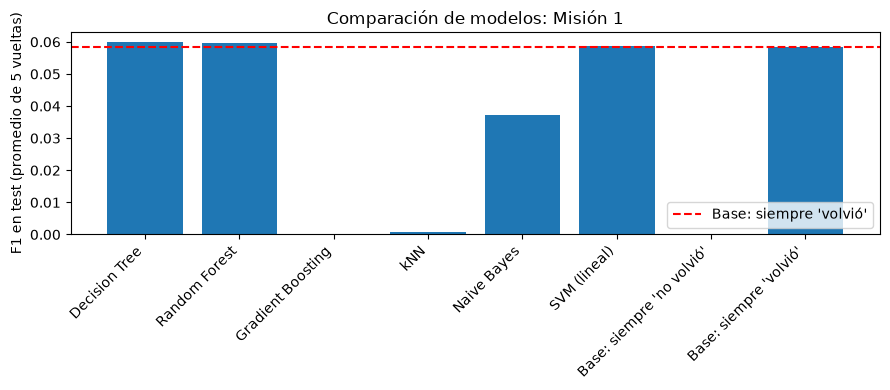

In [51]:
# guarda el valor del modelo de base para que se pueda ver sus diferencias.
base_volvio = tabla.loc["Base: siempre 'volvió'", "F1 test"]

plt.figure(figsize=(9, 4))
plt.bar(tabla.index, tabla["F1 test"])
plt.axhline(y=base_volvio, color="red", linestyle="--", label="Base: siempre 'volvió'")
plt.xticks(rotation=45, ha="right")
plt.ylabel("F1 en test (promedio de 5 vueltas)")
plt.title("Comparación de modelos: Misión 1")
plt.legend()
# ajusta los márgenes para que no se corten los nombres
plt.tight_layout()
plt.show()

Los modelos no son mucho mejores que el modelo base que responde siempre "volvió" con F1 = 0,058. Los únicos que lo superan apenas, son el Decision Tree, con 0,060, el Random Forest tambien con 0,060 y la SVM lineal con 0,059. Naive Bayes con 0,037 queda por debajo de la base, y Gradient Boosting con 0,000 y kNN con 0,001 casi nunca predicen que el cliente vuelve.

### Conclusiones de la Misión 1

La diferencia entre los tres mejores modelos es mínima porque tienen una mejora prácticamente nula con respecto al modelo base que dice a todos "vuelve", la diferencia entre ellos es de **0.001 a 0.002** desde el modelo base que tiene **F1 de 0.058**, a los demás modelos que son el **Decision Tree**, con **0,060**, el **Random Forest** también con **0,060** y la **SVM** lineal con **0,059**. Sin embargo, **Naive Bayes** queda por debajo de la base con **0,037** , y **Gradient Boosting** con **0,000** y **kNN** con **0,001**. Estos últimos tres modelos no admiten class_weight​ por ende compitieron en diferentes condiciones que los primeros 3 modelos, puede que eso explique los resultados tan distintos. Los resultados de las comparaciones sugieren que las columnas usadas no alcanzan para distinguir a quien vuelve. En el entrenamiento hay solo 4.251 combinaciones distintas de valores entre 74.686 filas. Una posible mejora sería sumar información de otras tablas, aunque no hay garantía de que ayude.

Se eligió usar **SVM Lineal** y no **SVM con kernels** por la diferencia de **velocidad** de ambos.

No se puede decir que el **Decision Tree** sea muy bueno para estos resultados puesto que la cantidad de clientes que dijo que volverían era de **40.840** del total del entrenamiento **74.686**, eso se puede traducir en que el modelo gastará demasiados recursos de la empresa para mantener a esos clientes, ofrecerles descuentos a todos ellos sería muy costoso. Su Precision fue de 0,031.

Otras posibles soluciones para esto aparte de sumar más pistas podría ser cambiar el valore de class_weight​ o ajustar algunos otros hiperparametros. En ningún caso hay garantía de que mejore.

**Utilizaría el modelo SVM lineal**. Porque su F1 en test es 0,059 es prácticamente igual al del Decision Tree y el Random Forest que son ambos 0,060, tiene **0,003 de brecha** entre train y test la menor de todos los modelos, por lo que es el modelo cuyo resultado parece más confiable. Aun así, no supera de forma clara al modelo base, así que esta elección es provisional hasta contar con mejores pistas.